In [205]:
####

# === Library Imports ===

# Standard Libraries
import os
import warnings
import logging
import json
import joblib
from datetime import datetime
from dataclasses import dataclass, field
from typing import Any, Dict, List, Callable, Optional

# Data Handling
import pandas as pd
import numpy as np
from openpyxl import Workbook
from openpyxl.styles import PatternFill, Alignment
import math

# Machine Learning
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import boxcox
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
import xgboost as xgb

# Models
import lightgbm as lgb
from catboost import CatBoostRegressor, Pool

# Visualization
import matplotlib.pyplot as plt
import shap

# SQL Utilities
from sqlalchemy import create_engine
from urllib.parse import quote_plus

# Custom Utilities
import utils.prediction_utils as pred
from utils import dictionaries as dictionary
from src.utils.query_dict import bucket_bounds, correction_factors
# from utils.logger import setup_logger  # Uncomment if needed

# === Jupyter Notebook Configuration ===

# Enable IPython to display all outputs for each cell
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

# === Warnings and Logging Configuration ===

# Suppress warnings
warnings.filterwarnings('ignore')
warnings.filterwarnings("ignore", category=UserWarning, module='lightgbm')

# Set logging for matplotlib and custom logger
plt.set_loglevel('warning')
logger = logging.getLogger("MyLogger")

# === Pandas Display Configuration ===
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)


In [206]:
def handle_model_training(model_handler, param_grid, model_name, results_dict, trainer, target_group):
    """
    Handle the training and tuning of a model dynamically.

    Parameters:
        model_handler (ModelHandler): The model handler instance (e.g., cat_handler, lgbm_handler).
        param_grid (dict): The parameter grid for tuning hyperparameters.
        model_name (str): The name of the model (e.g., "cat", "lgbm").
        results_dict (dict): The dictionary storing model results.
        trainer (Trainer): The trainer instance containing test data.
        target_group (str): The target group (e.g., "25-67").
    """

    def is_first_saturday_of_the_month():
        """Check if today is the first Saturday of the month."""
        today = datetime.now()
        return today.weekday() == 5 and 1 <= today.day <= 7

    if is_first_saturday_of_the_month():
        model_handler.tune_hyperparameters(param_grid=param_grid, n_iter=30)
        metrics = model_handler.evaluate(trainer.X_test, trainer.y_test)
        print(f"{model_name.upper()} Metrics After Tuning:", metrics)
    else:
        # Check if the target group and model exist in results_dict
        if target_group in results_dict and model_name in results_dict[target_group]:
            # Check if there are any entries for the model
            if results_dict[target_group][model_name]:
                # Fetch the latest best_params
                print(f"Latest best params for model '{model_name}' in target group '{target_group}':")
                model_handler.best_params = results_dict[target_group][model_name][
                    max(results_dict[target_group][model_name].keys(), key=lambda d: datetime.strptime(d, "%Y-%m-%d"))
                ]["best_params"]
            else:
                print(f"No entries for model '{model_name}' in target group '{target_group}'. Tuning hyperparameters.")
                model_handler.tune_hyperparameters(param_grid=param_grid, n_iter=30)
        else:
            print(f"Target group '{target_group}' or model '{model_name}' not found in results_dict. Tuning hyperparameters.")
            model_handler.tune_hyperparameters(param_grid=param_grid, n_iter=30)

# File path for storing results
results_file = "model_results.json"

def load_results():
    """Load results from JSON file if it exists."""
    if os.path.exists(results_file):
        with open(results_file, "r") as f:
            return json.load(f)
    return {}

def save_results(results_dict):
    """Save results dictionary to a JSON file."""
    with open(results_file, "w") as f:
        json.dump(results_dict, f, indent=4)
    print(f"Results saved to {results_file}")

def add_metrics_to_results_dict(results_dict, target_group, model_name, model_handler):
    """
    Add training and validation metrics from a ModelHandler instance to the results dictionary.

    Parameters:
        results_dict (dict): Dictionary to store the results.
        target_group (str): Target group name (e.g., "25-67").
        model_name (str): Model name (e.g., "lgbm").
        model_handler (ModelHandler): The ModelHandler instance containing the metrics.
        date (str): Date for the metrics entry (format: "YYYY-MM-DD").
        best_params (dict): Best parameters for the model.
    """
    date = datetime.now().strftime("%Y-%m-%d")
    # Ensure target group exists
    if target_group not in results_dict:
        results_dict[target_group] = {}

    # Ensure model exists and is a list
    if model_name not in results_dict[target_group]:
        results_dict[target_group][model_name] = {}

    results_dict[target_group][model_name][date] = {
        "metrics": {
            "train": {
                "mae": model_handler.train_mae,
                "mse": model_handler.train_mse,
                "rmse": model_handler.train_rmse,
                "r2": model_handler.train_r2,
            },
            "test": {
                "mae": model_handler.val_mae,
                "mse": model_handler.val_mse,
                "rmse": model_handler.val_rmse,
                "r2": model_handler.val_r2,
            }
        },
        "best_params": model_handler.best_params
    }


In [207]:
results_dict = load_results()

In [208]:
TRAIN_END_DATE = '2023-08-01'
VAL_END_DATE = '2024-09-30'
TEST_START_DATE = '2024-10-01'

TARGET = 'ster_1+_total'
TARGET_GROUP = '50+'

NUMERICAL_COLS = ['npo1_grp_daynight', 'npo1_grp_primetime',
                  'npo2_grp_daynight', 'npo2_grp_primetime',
                  'npo3_grp_daynight', 'npo3_grp_primetime',
                  'regio_grp_daynight', 'regio_grp_primetime',
                  'timef_olympic_period_overlap', 'timef_football_period_overlap',
                  'timef_duration_days',
                  'timef_start_month',
                  'timef_start_year',
                  'timef_start_week',
                ]

CATEGORICAL_COLS = [
                    # 'timef_start_season',
                    # 'timef_end_season'
                    ]

BOOLEAN_COLS = [
                'alcohol_kansspelen',
                'is_olympic_period',
                'is_football_period',
                ]

FEATURES = NUMERICAL_COLS + CATEGORICAL_COLS + BOOLEAN_COLS

In [209]:
@dataclass
class ModelTrainer:
    # SQL Query and Data Preparation
    target_group: str
    train_end_date: str
    val_end_date: str
    test_start_date: str
    features: List[str]
    target: str
    numerical_cols: List[str]
    categorical_cols: List[str]
    boolean_cols: List[str]

    bucket_bounds: dict = field(default_factory=lambda: bucket_bounds)
    correction_factors: dict = field(default_factory=lambda: correction_factors)

    # Preprocessing and Model Setup
    df: pd.DataFrame = None
    preprocessor: Optional[ColumnTransformer] = None
    feature_names: List[str] = field(default_factory=list)
    X_train: np.ndarray = None
    y_train: np.ndarray = None
    X_val: np.ndarray = None
    y_val: np.ndarray = None
    X_test: np.ndarray = None
    y_test: np.ndarray = None

    train_data: pd.DataFrame = field(init=False)
    val_data: pd.DataFrame = field(init=False)
    test_data: pd.DataFrame = field(init=False)

    # Model-related fields
    model: Any = None
    params: Dict[str, Any] = field(default_factory=dict)

    def __post_init__(self):
        # This runs when creating model class. Automatically fetches data and sets up preprocessor
        self.create_preprocessor()
        query = self.construct_query()
        df = self.query_to_df(query)
        self.df = self.prep_dataframe(df)
        self.apply_correction(self.df)
        self.split_and_preprocess()
        self.get_feature_names(self.preprocessor)

    def construct_query(self):
        """
        Constructs an SQL query to fetch the required data based on the target group.
        """
        target_group_str = (
            ', '.join([f"'{tg}'" for tg in self.target_group])
            if isinstance(self.target_group, (list, tuple))
            else f"'{self.target_group}'"
        )
        return f"""
            SELECT b.flight_id,
                   b.target_group,
                   f.advertiser,
                   f.product,
                   f.start_date,
                   f.end_date,
                   b.campaign_duration,
                   b.daypart,
                   f.mock_campaign,
                   f.alcohol_kansspelen,
                   b.ster_grp,
                   b.regio_grp,
                   b.npo1_grp,
                   b.npo2_grp,
                   b.npo3_grp,
                   b.[ster_1+]
            FROM [dbo].[tv.bereik_ster] b
            LEFT JOIN [dbo].[tv.flights_ster] f ON b.flight_id = f.flight_id
            WHERE b.ster_grp > 0
            AND target_group IN ({target_group_str})
            AND b.campaign_duration >= 7
            ORDER BY start_date;
        """

    def create_sql_alchemy_engine(self):
        """
        Creates and returns a SQLAlchemy engine for connecting to a SQL Server database.
        """
        quoted = quote_plus(
            "Driver={ODBC+Driver+17+for+SQL+Server};"
            "Server=tcp:stercampsql.database.windows.net;"
            "Database=SterCampNew;"
            "uid=stercampadmin;"
            f"pwd={os.getenv('SQLDB')}"
        )
        return create_engine(f"mssql+pyodbc:///?odbc_connect={quoted}")

    def query_to_df(self, query: str):
        """
        Executes the SQL query and returns the result as a DataFrame.
        """
        engine = self.create_sql_alchemy_engine()
        return pd.read_sql_query(query, engine)

    def prep_dataframe(self, df):
        df = df[["flight_id", "target_group", "start_date", "end_date", "advertiser", "product", "daypart", "mock_campaign", "alcohol_kansspelen",
                        "npo1_grp", "npo2_grp", "npo3_grp", "regio_grp", "ster_grp",
                        "ster_1+"]].reset_index(drop=True)

        df = (df.pivot_table(index=["flight_id", "target_group", "start_date", "end_date", 'advertiser', 'product', "mock_campaign", "alcohol_kansspelen"],
                            columns='daypart', fill_value=0.0,
                            values=['npo1_grp', 'npo2_grp', 'npo3_grp',
                                    'ster_grp', 'ster_1+', 'regio_grp'], aggfunc='sum').reset_index())


        df.columns = ["_".join(col) if col[1] else col[0] for col in df.columns.to_flat_index()]

        # Convert start_date and end_date to datetime objects and calculate required values
        df['start_date'] = pd.to_datetime(df['start_date'], format="%d%m%y", errors='coerce')
        df['end_date'] = pd.to_datetime(df['end_date'], format="%d%m%y", errors='coerce')

        # Apply function to create extra columns
        df['timef_start_month'] = df['start_date'].dt.month
        df['timef_end_month'] = df['end_date'].dt.month
        df['timef_start_year'] = df['start_date'].dt.year
        df['timef_end_year'] = df['end_date'].dt.year
        df['timef_start_week'] = df['start_date'].dt.strftime("%V").astype(int)
        df['timef_end_week'] = df['end_date'].dt.strftime("%V").astype(int)
        df['timef_start_day'] = df['start_date'].dt.day
        df['timef_end_day'] = df['end_date'].dt.day
        df['timef_duration_days'] = df.apply(lambda row: (row['end_date'] - row['start_date']).days + 1, axis=1)

        df['timef_start_season'] = df['timef_start_month'].apply(lambda month: 'Winter' if month in [12, 1, 2] else
                                                      'Spring' if month in [3, 4, 5] else
                                                      'Summer' if month in [6, 7, 8] else
                                                      'Autumn')
        df['timef_end_season'] = df['timef_end_month'].apply(lambda month: 'Winter' if month in [12, 1, 2] else
                                                    'Spring' if month in [3, 4, 5] else
                                                    'Summer' if month in [6, 7, 8] else
                                                    'Autumn')

        # Calculate total overlap with olympics and WK/EK
        df['timef_olympic_period_overlap'] = df.apply(pred.calculate_total_overlap, axis=1, period_list=(dictionary.olympic_period_list))
        df['timef_football_period_overlap'] = df.apply(pred.calculate_total_overlap, axis=1, period_list=(dictionary.football_wk_ek_list))

        # Create interaction features
        df['grp_olympic_overlap'] = df['ster_grp_total'] * df['timef_olympic_period_overlap']
        df['grp_football_overlap'] = df['ster_grp_total'] * df['timef_football_period_overlap']

        # Create binary indicators
        df['is_olympic_period'] = (df['timef_olympic_period_overlap'] > 0).astype(int)
        df['is_football_period'] = (df['timef_football_period_overlap'] > 0).astype(int)

        # Create a new column 'new_data' indicating old or new
        df['new_data'] = pd.cut(
            df['start_date'],
            bins=[pd.Timestamp.min, pd.to_datetime('2023-09-01'), pd.Timestamp.max],
            labels=[0, 1])

        # Add n random rows that have a base value of 0 GRPs and bereik
        non_grp_columns = ['start_date', 'end_date', 'timef_duration_days', 'timef_olympic_period_overlap', 'timef_football_period_overlap',
                            'timef_start_day', 'timef_end_day', 'timef_start_week', 'timef_end_week', 'timef_start_month',
                            'timef_end_month', 'timef_start_year', 'timef_end_year', 'timef_start_season', 'timef_end_season',
                            'target_group', 'advertiser', 'product', 'mock_campaign', 'alcohol_kansspelen', 'new_data']

        # Sample 600 random rows with 0 GRPs and bereik
        sampled_df = df.sample(n=600, random_state=42).reset_index(drop=True)
        sampled_df_zeroed = sampled_df.copy()
        for column in sampled_df_zeroed.columns:
            if column not in non_grp_columns:
                sampled_df_zeroed[column] = 0

        df_combined = pd.concat([df, sampled_df_zeroed], ignore_index=True)

        df = df_combined.sort_values(by=['start_date', 'advertiser', 'product', 'end_date'])

        # def shift_to_positive(column):
        #     if column.min() <= 0:
        #         return column + abs(column.min()) + 1
        #     return column

        # # Ensure positive values
        # df["npo3_grp_daynight"] = shift_to_positive(df["npo3_grp_daynight"])
        # df["npo3_grp_primetime"] = shift_to_positive(df["npo3_grp_primetime"])

        # # Apply Box-Cox transformation
        # transformed_data_daynight, lambda_value = boxcox(df["npo3_grp_daynight"])
        # transformed_data_primetime, lambda_value = boxcox(df["npo3_grp_primetime"])

        # # Store the transformed column and lambda
        # df["npo3_grp_daynight"] = transformed_data_daynight
        # df["npo3_grp_primetime"] = transformed_data_primetime

        ########## Filter Outliers ##########

        q_low = df['ster_grp_total'].quantile(0.01)
        q_hi  = df['ster_grp_total'].quantile(0.99)
        df = df[(df['ster_grp_total'] < q_hi) & (df['ster_grp_total'] > q_low)]

        q_low = df['ster_1+_total'].quantile(0.01)
        q_hi  = df['ster_1+_total'].quantile(0.99)
        df = df[(df['ster_1+_total'] < q_hi) & (df['ster_1+_total'] > q_low)]

        ##############################################

        return df

    def _get_bucket(self, target_group, ster_grp):
        """
        Determine the bucket for a given ster_grp value based on the bucket boundaries.

        :param target_group: The target group of the row.
        :param ster_grp: The ster_grp value of the row.
        :return: The bucket index (integer).
        """
        bounds = self.bucket_bounds.get(target_group, [0, np.inf])
        for i in range(len(bounds) - 1):
            if bounds[i] <= ster_grp < bounds[i + 1]:
                return i
        return len(bounds) - 2  # Default to the last bucket if not explicitly matched

    def apply_correction(self, df):
        """
        Apply the correction to the ster_1+ column in the DataFrame based on the bucket boundaries and correction factors.

        :param df: Input DataFrame containing 'target_group', 'ster_grp', 'ster_1+', and 'date'.
        :return: DataFrame with a new column 'corrected_ster_1+'.
        """
        def correct_row(row):
            if pd.to_datetime(row['start_date']) >= pd.Timestamp('2023-08-01'):
                return row['ster_1+_total']  # No correction applied after 08-2023
            bucket = self._get_bucket(row['target_group'], row['ster_grp_total'])
            correction_factor = self.correction_factors.get((row['target_group'], bucket), 1)
            if correction_factor is not None:
                return row['ster_1+_total'] * correction_factor
            return row['ster_1+_total']

        df['corrected_ster_1+'] = df.apply(correct_row, axis=1)
        # df['ster_1+_total'] = df.apply(correct_row, axis=1).round(1)

        return df

    def create_preprocessor(self):
        """
        Creates and configures the preprocessing pipeline.
        """
        transformers = []

        if self.numerical_cols:
            numerical_transformer = Pipeline(
                steps=[('imputer', SimpleImputer(strategy='mean'))]
            )
            transformers.append(('num', numerical_transformer, self.numerical_cols))

        if self.categorical_cols:
            categorical_transformer = Pipeline(
                steps=[
                    ('imputer', SimpleImputer(strategy='most_frequent')),
                    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first')),
                ]
            )
            transformers.append(('cat', categorical_transformer, self.categorical_cols))

        if self.boolean_cols:
            boolean_transformer = Pipeline(
                steps=[
                    ('int_conversion', FunctionTransformer(lambda x: x.astype(int), validate=False)),
                    ('imputer', SimpleImputer(strategy='most_frequent')),
                ]
            )
            transformers.append(('bool', boolean_transformer, self.boolean_cols))

        self.preprocessor = ColumnTransformer(transformers=transformers)

    def get_feature_names(self, preprocessor):
        feature_names = []

        # Get numerical feature names
        if 'num' in preprocessor.named_transformers_:
            feature_names += self.numerical_cols

        # Get categorical feature names
        if 'cat' in preprocessor.named_transformers_:
            encoder = preprocessor.named_transformers_['cat'].named_steps['onehot']
            cat_feature_names = encoder.get_feature_names_out(self.categorical_cols)
            feature_names += cat_feature_names.tolist()

        # Get boolean feature names
        if 'bool' in preprocessor.named_transformers_:
            feature_names += self.boolean_cols

        self.feature_names = feature_names

        return feature_names

    def split_and_preprocess(self):
        """
        Splits the data by date ranges, preprocesses, and transforms datasets.
        """
        df = self.df.copy()
        df['start_date'] = pd.to_datetime(df['start_date'])

        self.train_data = df[df['start_date'] < pd.Timestamp(self.train_end_date)]
        self.val_data = df[
            (df['start_date'] >= pd.Timestamp(self.train_end_date))
            & (df['start_date'] <= pd.Timestamp(self.val_end_date))
        ]
        self.test_data = df[df['start_date'] >= pd.Timestamp(self.test_start_date)]

        self.preprocessor.fit(self.train_data[self.features])
        self.X_train = self.preprocessor.transform(self.train_data[self.features])
        self.y_train = self.train_data[self.target].values
        self.X_val = self.preprocessor.transform(self.val_data[self.features])
        self.y_val = self.val_data[self.target].values
        self.X_test = self.preprocessor.transform(self.test_data[self.features])
        self.y_test = self.test_data[self.target].values


In [210]:
@dataclass
class ModelHandler:
    trainer: ModelTrainer  # Instance of the ModelTrainer class
    model_class: Callable  # Model class (e.g., CatBoostRegressor, LGBMRegressor, etc.)
    params: Dict[str, Any] = field(default_factory=dict)  # Model parameters
    best_params: dict = field(init=False, default_factory=dict)
    model: Any = None  # Initialized model instance
    evals_result: Dict[str, Dict[str, List[float]]] = field(default_factory=dict)  # For storing evaluation results

    # Training Metrics
    train_mae: float = field(init=False, default=None)
    train_mse: float = field(init=False, default=None)
    train_rmse: float = field(init=False, default=None)
    train_r2: float = field(init=False, default=None)

    # Validation Metrics
    val_mae: float = field(init=False, default=None)
    val_mse: float = field(init=False, default=None)
    val_rmse: float = field(init=False, default=None)
    val_r2: float = field(init=False, default=None)

    def __post_init__(self):
        """
        Initialize the model instance with the provided parameters.
        """
        self.model = self.model_class(**self.params)

    def train(self, **kwargs):
        """
        Train the model using the training data from the ModelTrainer instance.
        Supports LightGBM, XGBoost, and CatBoost with early stopping and evaluation history.

        Parameters:
        - **kwargs: Additional keyword arguments for model training or callbacks.
        """
        # Use best parameters if available
        if hasattr(self, "best_params") and self.best_params:
            print(f"Using best parameters for {self.model_class.__name__}: {self.best_params}")
            self.params.update(self.best_params)
        else:
            print(f"Using default parameters for {self.model_class.__name__}.")

        print(f"Training {self.model_class.__name__}...")

        self.evals_result = {}

        if self.model_class.__name__ == "LGBMRegressor":
            # Convert data to LightGBM Datasets
            train_data = lgb.Dataset(self.trainer.X_train, label=self.trainer.y_train)
            val_data = lgb.Dataset(self.trainer.X_val, label=self.trainer.y_val, reference=train_data)

            def record_evals_result(env):
                """Custom callback to record evaluation results."""
                for data_name, eval_name, result, _ in env.evaluation_result_list:
                    if data_name not in self.evals_result:
                        self.evals_result[data_name] = {}
                    if eval_name not in self.evals_result[data_name]:
                        self.evals_result[data_name][eval_name] = []
                    self.evals_result[data_name][eval_name].append(result)

            # Initialize evaluation result storage
            self.evals_result = {}

            # Train the model with LightGBM's native API
            self.model = lgb.train(
                params=self.best_params,
                train_set=train_data,
                valid_sets=[train_data, val_data],  # Include both training and validation sets
                num_boost_round=kwargs.get("num_boost_round", 3000),
                callbacks=[
                    lgb.early_stopping(stopping_rounds=kwargs.get("early_stopping_rounds", 100)),
                    lgb.log_evaluation(period=kwargs.get("verbose", 100)),
                    record_evals_result
                ]
            )

            print(f"Best iteration: {self.model.best_iteration}")
            print(f"Best score on validation set: {self.model.best_score}")

        elif self.model_class.__name__ in ["XGBRegressor"]:
            self.best_params["early_stopping_rounds"] = kwargs.get("early_stopping_rounds", 100)
            self.model = self.model_class(**self.best_params)
            self.model.fit(
                self.trainer.X_train,
                self.trainer.y_train,
                eval_set=[(self.trainer.X_train, self.trainer.y_train), (self.trainer.X_val, self.trainer.y_val)],
                verbose = True,
            )

            # Save evaluation results for plotting
            self.evals_result = self.model.evals_result_
            print(f"Best iteration: {self.model.best_iteration}")
            print(f"Best score on validation set: {self.model.best_score}")

        elif self.model_class.__name__ == "CatBoostRegressor":
            self.model.fit(
                self.trainer.X_train,
                self.trainer.y_train,
                eval_set=[(self.trainer.X_train, self.trainer.y_train), (self.trainer.X_val, self.trainer.y_val)],
                early_stopping_rounds=kwargs.get("early_stopping_rounds", 100),
                verbose=kwargs.get("verbose", 100),
            )
            # Get evaluation results for all iterations
            self.evals_result = self.model.get_evals_result()

        else:
            # Fallback for other models
            self.model.fit(self.trainer.X_train, self.trainer.y_train, **kwargs)

        print(f"{self.model_class.__name__} training complete.")

    def plot_learning_curve(self, save_filename="learning_curve.png"):
        """
        Plot the learning curve using evaluation results and save it to a file.

        Parameters:
            save_filename (str): The name of the file to save the plot.
        """
        if not self.evals_result:
            print("No evaluation results to plot.")
            return

        print("Plotting and saving learning curve...")

        # Plot learning curves
        plt.figure(figsize=(10, 6))
        for data_name, metrics in self.evals_result.items():
            for metric_name, results in metrics.items():
                plt.plot(results, label=f"{data_name} - {metric_name}")
        plt.xlabel("Iterations")
        plt.ylabel("Metric")
        plt.title(f"Learning Curve - {self.model_class.__name__}")
        plt.legend()
        plt.grid(True)

        # Save the plot to the current folder
        save_path = os.path.join(os.getcwd(), save_filename)
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        plt.close()

    def predict(self, X):
        """
        Make predictions using the trained model.
        """
        if not self.model:
            raise ValueError("Model is not trained.")
        return self.model.predict(X)

    def evaluate(self, X, y):
        """
        Evaluate the model on the given data.
        """
        predictions = self.predict(X)
        mse = mean_squared_error(y, predictions)
        rmse = math.sqrt(mse)
        mae = mean_absolute_error(y, predictions)
        r2 = r2_score(y, predictions)
        return {"MSE": mse, "RMSE": rmse, "MAE": mae, "R²": r2}

    def display_metrics(self, y_train_true, y_train_pred, y_val_true, y_val_pred):
        """
        Display regression metrics (MAE, MSE, RMSE, R²) for both training and validation sets.

        Parameters:
        - y_train_true (array-like): True target values for the training set.
        - y_train_pred (array-like): Predicted target values for the training set.
        - y_val_true (array-like): True target values for the validation set.
        - y_val_pred (array-like): Predicted target values for the validation set.

        Returns:
        None (prints metrics directly)
        """
        # Training Metrics
        self.train_mae = round(mean_absolute_error(y_train_true, y_train_pred), 2)
        self.train_mse = round(mean_squared_error(y_train_true, y_train_pred), 2)
        self.train_rmse = round(np.sqrt(self.train_mse), 2)
        self.train_r2 = round(r2_score(y_train_true, y_train_pred), 2)

        # Validation Metrics
        self.val_mae = round(mean_absolute_error(y_val_true, y_val_pred), 2)
        self.val_mse = round(mean_squared_error(y_val_true, y_val_pred), 2)
        self.val_rmse = round(np.sqrt(self.val_mse), 2)
        self.val_r2 = round(r2_score(y_val_true, y_val_pred), 2)

        # Display Metrics
        print("Training Set Metrics:")
        print(f"  MAE: {self.train_mae:.4f}")
        print(f"  MSE: {self.train_mse:.4f}")
        print(f"  RMSE: {self.train_rmse:.4f}")
        print(f"  R²: {self.train_r2:.4f}")

        print("\nValidation Set Metrics:")
        print(f"  MAE: {self.val_mae:.4f}")
        print(f"  MSE: {self.val_mse:.4f}")
        print(f"  RMSE: {self.val_rmse:.4f}")
        print(f"  R²: {self.val_r2:.4f}")

    def tune_hyperparameters(self, param_grid: Dict[str, List[Any]], n_iter: int = 10, cv: int = 5, scoring: str = 'neg_mean_squared_error'):
        """
        Perform hyperparameter tuning using RandomizedSearchCV.
        """
        print(f"Tuning hyperparameters for {self.model_class.__name__}...")
        search = RandomizedSearchCV(
            estimator=self.model_class(),
            param_distributions=param_grid,
            n_iter=n_iter,
            scoring=scoring,
            cv=cv,
            verbose=1,
            random_state=42,
            n_jobs=-1
        )
        search.fit(self.trainer.X_train, self.trainer.y_train)
        self.model = search.best_estimator_
        self.best_params = search.best_params_
        print(f"Best parameters: {self.best_params}")

    def predict_and_export_to_excel(self, model, file_path="test_predictions.xlsx"):
        """
        Predicts on self.test_data and exports the results, including target, prediction, and residuals, to an Excel file.

        Parameters:
        - file_path (str): The path to save the Excel file. Default is "test_predictions.xlsx".
        """
        if type(model) == lightgbm.basic.Booster:
            model_prefix = "lgb"
        elif type(model) == xgboost.core.Booster:
            model_prefix = "xgb"
        elif type(model) == catboost.core.CatBoostRegressor:
            model_prefix = "cat"

        df_test = self.trainer.test_data.copy()

        # Predict on the test set
        predictions = model.predict(self.trainer.X_test)

        # Add predictions and residuals to the test dataframe
        df_test[f"prediction_{model_prefix}"] = predictions
        df_test[self.target] = self.trainer.y_test.flatten()
        df_test[f"residual_{model_prefix}"] = df_test[self.trainer.target] - df_test[f"prediction_{model_prefix}"]

        # Round the numerical values for better readability
        df_test[[f"prediction_{model_prefix}", self.trainer.target, f"residual_{model_prefix}"]] = df_test[[f"prediction_{model_prefix}", self.trainer.target, f"residual_{model_prefix}"]].round(2)

        # Select relevant columns
        df_test = df_test[[
            'flight_id', 'target_group', 'start_date', 'end_date', 'timef_duration_days', 'advertiser',
            'product', 'alcohol_kansspelen', 'npo1_grp_daynight',
            'npo1_grp_primetime', 'npo1_grp_total', 'npo2_grp_daynight',
            'npo2_grp_primetime', 'npo2_grp_total', 'npo3_grp_daynight',
            'npo3_grp_primetime', 'npo3_grp_total', 'regio_grp_daynight',
            'regio_grp_primetime', 'regio_grp_total', 'ster_grp_total',
            'ster_1+_total', 'prediction_lgb', 'residual_lgb'
        ]]

        # Calculate metrics
        test_mae = mean_absolute_error(self.trainer.y_test, predictions)
        test_mse = mean_squared_error(self.trainer.y_test, predictions)
        test_rmse = np.sqrt(test_mse)
        test_r2 = r2_score(self.trainer.y_test, predictions)

        # Display Metrics
        print("Test Set Metrics:")
        print(f"  MAE: {test_mae:.4f}")
        print(f"  MSE: {test_mse:.4f}")
        print(f"  RMSE: {test_rmse:.4f}")
        print(f"  R²: {test_r2:.4f}")

        df_test.to_excel(file_path, index = False)

    def save_model(self, model, prefix, target_group):
        """
        Save the trained model to a file. Uses a default file path if none is provided.
        """
        # Define default directory and file name
        default_dir = os.path.join(os.getcwd(), "best_models")

        # Ensure the default directory exists
        if not os.path.exists(default_dir):
            os.makedirs(default_dir)

        # Use default path if file_path is not provided
        file_path = os.path.join(default_dir, f'{prefix}_{target_group}')

        # Save the model
        joblib.dump(model.model, file_path)
        print(f"Model saved to {file_path}")

    def load_model(self, file_path=None):
        """
        Load a trained model from a file. Uses a default file path if none is provided.
        """
        # Define default directory and file name
        default_dir = os.path.join(os.getcwd(), "best_models")

        # Use default path if file_path is not provided
        if file_path is None:
            file_path = os.path.join(default_dir, default_file)

        # Check if the file exists
        if not os.path.exists(file_path):
            raise FileNotFoundError(f"Model file not found at {file_path}")

        # Load the model
        self.best_model = joblib.load(file_path)
        print(f"Model loaded from {file_path}")


In [211]:
trainer = ModelTrainer(
    target_group= TARGET_GROUP,
    train_end_date= TRAIN_END_DATE,
    val_end_date= VAL_END_DATE,
    test_start_date= TEST_START_DATE,
    features = FEATURES,
    target= TARGET,
    numerical_cols= NUMERICAL_COLS,
    categorical_cols= CATEGORICAL_COLS,
    boolean_cols= BOOLEAN_COLS
)

In [212]:
trainer.train_data.head(2)
trainer.test_data.head(2)

,flight_id,target_group,start_date,end_date,advertiser,product,mock_campaign,alcohol_kansspelen,npo1_grp_daynight,npo1_grp_primetime,npo1_grp_total,npo2_grp_daynight,npo2_grp_primetime,npo2_grp_total,npo3_grp_daynight,npo3_grp_primetime,npo3_grp_total,regio_grp_daynight,regio_grp_primetime,regio_grp_total,ster_1+_daynight,ster_1+_primetime,ster_1+_total,ster_grp_daynight,ster_grp_primetime,ster_grp_total,timef_start_month,timef_end_month,timef_start_year,timef_end_year,timef_start_week,timef_end_week,timef_start_day,timef_end_day,timef_duration_days,timef_start_season,timef_end_season,timef_olympic_period_overlap,timef_football_period_overlap,grp_olympic_overlap,grp_football_overlap,is_olympic_period,is_football_period,new_data,corrected_ster_1+
88440,b87d8a9a-025c-16e5-2dbe-02799026009e,50+,2018-01-01,2018-01-13,Abn amro,Abn-amro,False,False,0.00,71.45,71.45,0.0,69.17,69.17,0.00,8.74,8.74,0.0,0.0,0.0,0.00,56.80,56.80,0.00,149.36,149.36,1,1,2018,2018,1,2,1,13,13,Winter,Winter,0,0,0.0,0.0,0,0,0,52.824
69961,91b826e6-67fc-f44e-7c15-5eed5a086038,50+,2018-01-01,2018-01-08,Achmea holding,Centraal beheer,True,False,8.99,0.00,8.99,0.0,6.49,6.49,0.36,3.85,4.21,0.0,0.0,0.0,9.45,9.64,17.37,9.35,10.34,19.69,1,1,2018,2018,1,2,1,8,8,Winter,Winter,0,0,0.0,0.0,0,0,0,19.107


,flight_id,target_group,start_date,end_date,advertiser,product,mock_campaign,alcohol_kansspelen,npo1_grp_daynight,npo1_grp_primetime,npo1_grp_total,npo2_grp_daynight,npo2_grp_primetime,npo2_grp_total,npo3_grp_daynight,npo3_grp_primetime,npo3_grp_total,regio_grp_daynight,regio_grp_primetime,regio_grp_total,ster_1+_daynight,ster_1+_primetime,ster_1+_total,ster_grp_daynight,ster_grp_primetime,ster_grp_total,timef_start_month,timef_end_month,timef_start_year,timef_end_year,timef_start_week,timef_end_week,timef_start_day,timef_end_day,timef_duration_days,timef_start_season,timef_end_season,timef_olympic_period_overlap,timef_football_period_overlap,grp_olympic_overlap,grp_football_overlap,is_olympic_period,is_football_period,new_data,corrected_ster_1+
39996,5360f308-ca9a-3fc7-b4c2-625a3ebab39e,50+,2024-10-01,2024-10-19,Abn amro,Abn-amro,True,False,103.01,71.37,174.38,21.38,2.52,23.90,1.28,6.65,7.93,0.13,0.23,0.35,36.83,39.51,55.75,125.79,80.77,206.57,10,10,2024,2024,40,42,1,19,19,Autumn,Autumn,0,0,0.0,0.0,0,0,1,55.75
37358,4dde5797-8252-01cf-2bec-c37a26d5f56a,50+,2024-10-01,2024-10-27,Abn amro,Abn-amro,False,False,150.94,92.06,243.00,27.07,2.52,29.59,2.70,6.65,9.35,0.13,0.23,0.35,42.23,45.51,62.32,180.84,101.46,282.30,10,10,2024,2024,40,43,1,27,27,Autumn,Autumn,0,0,0.0,0.0,0,0,1,62.32


## LGBM Regressor

In [ ]:
param_grid_lgbm = {
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "n_estimators": [100, 200, 300, 500, 800, 1000],
    "max_depth": [3, 5, 8, 12, 15, -1],
    "num_leaves": [15, 31, 50, 70, 100, 150],
    "min_child_samples": [10, 20, 50, 100],
    "min_child_weight": [1e-3, 1e-2, 0.1, 1.0],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "reg_alpha": [0.5, 1.0, 1.5, 2.0],
    "reg_lambda": [0.0, 0.1, 0.5, 1.0, 1.5],
    "boosting_type": ["gbdt", "dart", "goss"],
    "objective": ["regression"]
}

lgb_handler = ModelHandler(
    trainer=trainer,
    model_class=lgb.LGBMRegressor,
    params=param_grid_lgbm
)

handle_model_training(lgb_handler, param_grid_lgbm, 'lgbm', results_dict, trainer, TARGET_GROUP)

Target group '50+' or model 'lgbm' not found in results_dict. Tuning hyperparameters.
Tuning hyperparameters for LGBMRegressor...
Fitting 5 folds for each of 30 candidates, totalling 150 fits


In [ ]:
lgb_handler.train(
    eval_metric="rmse",
    early_stopping_rounds=100,
    verbose=100
)

lgb_handler.plot_learning_curve(save_filename=f"lgbm_learning_curve_{TARGET_GROUP}.png")

y_train_pred = lgb_handler.model.predict(trainer.X_train)
y_val_pred = lgb_handler.model.predict(trainer.X_val)
lgb_handler.display_metrics(trainer.y_train, y_train_pred, trainer.y_val, y_val_pred)

Using best parameters for LGBMRegressor: {'subsample': 0.8, 'reg_lambda': 1.5, 'reg_alpha': 2.0, 'objective': 'regression', 'num_leaves': 50, 'n_estimators': 200, 'min_child_weight': 0.01, 'min_child_samples': 20, 'max_depth': -1, 'learning_rate': 0.05, 'colsample_bytree': 0.8, 'boosting_type': 'goss'}
Training LGBMRegressor...
[LightGBM] [Warning] Found boosting=goss. For backwards compatibility reasons, LightGBM interprets this as boosting=gbdt, data_sample_strategy=goss.To suppress this warning, set data_sample_strategy=goss instead.
[LightGBM] [Warning] Found boosting=goss. For backwards compatibility reasons, LightGBM interprets this as boosting=gbdt, data_sample_strategy=goss.To suppress this warning, set data_sample_strategy=goss instead.
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.009160 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] 

In [ ]:
add_metrics_to_results_dict(results_dict, TARGET_GROUP, 'lgbm', lgb_handler)
save_results(results_dict)

Results saved to model_results.json


In [ ]:
# lgb_handler.save_model(lgb_handler, 'lgb', TARGET_GROUP)

## XGBRegressor

In [ ]:
## Used for tuning
param_grid_xgb = {
    "learning_rate": [0.02, 0.03, 0.04, 0.05, 0.1, 0.2],        # Focused around the best rate
    "n_estimators": [200, 600, 800, 1000],                # Explore slightly fewer and more rounds
    "max_depth": [4, 5, 6, 10],                          # Narrow range around the best depth
    "min_child_weight": [1, 2, 3, 8],                   # Slightly higher regularization values
    "subsample": [0.6, 0.8, 1.0],                    # Focus near the best subsample
    "colsample_bytree": [0.3, 0.5, 0.6, 0.7],             # Explore values around the best
    "reg_alpha": [0.3, 0.5, 0.7, 1.0],                    # Narrow range around the best alpha
    "reg_lambda": [1.0, 1.5, 2.0, 2.5],                   # Slightly broaden the lambda range
    "gamma": [0, 0.1, 0.2],                          # Small values for split regularization
    "tree_method": ["hist"],                         # Fixed as it performed best
    "objective": ["reg:squarederror"],               # Fixed for regression
    "scale_pos_weight": [1],                         # Fixed for balanced dataset
}

xgb_handler = ModelHandler(
    trainer=trainer,
    model_class=XGBRegressor,
    params=param_grid
)

handle_model_training(xgb_handler, param_grid_xgb, 'xgb', results_dict, trainer, TARGET_GROUP)

Target group '20-49' or model 'xgb' not found in results_dict. Tuning hyperparameters.
Tuning hyperparameters for XGBRegressor...
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best parameters: {'tree_method': 'hist', 'subsample': 0.6, 'scale_pos_weight': 1, 'reg_lambda': 2.5, 'reg_alpha': 0.3, 'objective': 'reg:squarederror', 'n_estimators': 600, 'min_child_weight': 8, 'max_depth': 6, 'learning_rate': 0.04, 'gamma': 0.1, 'colsample_bytree': 0.6}


In [ ]:
xgb_handler.train(early_stopping_rounds=100)
xgb_handler.plot_learning_curve(save_filename=f"xgb_learning_curve_{TARGET_GROUP}.png")

y_train_pred = xgb_handler.model.predict(trainer.X_train)
y_val_pred = xgb_handler.model.predict(trainer.X_val)

xgb_handler.display_metrics(trainer.y_train, y_train_pred, trainer.y_val, y_val_pred)

Using best parameters for XGBRegressor: {'tree_method': 'hist', 'subsample': 0.6, 'scale_pos_weight': 1, 'reg_lambda': 2.5, 'reg_alpha': 0.3, 'objective': 'reg:squarederror', 'n_estimators': 600, 'min_child_weight': 8, 'max_depth': 6, 'learning_rate': 0.04, 'gamma': 0.1, 'colsample_bytree': 0.6}
Training XGBRegressor...
[0]	validation_0-rmse:12.41400	validation_1-rmse:11.74561
[1]	validation_0-rmse:11.99865	validation_1-rmse:11.33595
[2]	validation_0-rmse:11.60312	validation_1-rmse:10.95022
[3]	validation_0-rmse:11.22565	validation_1-rmse:10.57995
[4]	validation_0-rmse:10.94608	validation_1-rmse:10.32846
[5]	validation_0-rmse:10.59527	validation_1-rmse:9.98427
[6]	validation_0-rmse:10.43894	validation_1-rmse:9.85878
[7]	validation_0-rmse:10.19312	validation_1-rmse:9.65614
[8]	validation_0-rmse:9.88706	validation_1-rmse:9.38119
[9]	validation_0-rmse:9.58198	validation_1-rmse:9.07902
[10]	validation_0-rmse:9.28221	validation_1-rmse:8.78387
[11]	validation_0-rmse:9.00606	validation_1-rmse

In [ ]:
add_metrics_to_results_dict(results_dict, TARGET_GROUP, 'xgb', xgb_handler)
save_results(results_dict)

Results saved to model_results.json


## CatBoost

In [ ]:
param_grid_cat = {
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "depth": [4, 6, 8, 10],
    "iterations": [1000, 1500, 2000, 3000],
    "l2_leaf_reg": [3, 5, 7, 9]
}

cat_handler = ModelHandler(
    trainer=trainer,
    model_class=CatBoostRegressor,
    params=param_grid_cat
)

handle_model_training(cat_handler, param_grid_cat, 'cat', results_dict, trainer, TARGET_GROUP)

Target group '20-49' or model 'cat' not found in results_dict. Tuning hyperparameters.
Tuning hyperparameters for CatBoostRegressor...
Fitting 5 folds for each of 30 candidates, totalling 150 fits
0:	learn: 12.7287592	total: 17.3ms	remaining: 51.8s
1:	learn: 12.6262565	total: 35.1ms	remaining: 52.6s
2:	learn: 12.5247480	total: 48.4ms	remaining: 48.4s
3:	learn: 12.4230286	total: 61ms	remaining: 45.7s
4:	learn: 12.3232440	total: 80.9ms	remaining: 48.5s
5:	learn: 12.2245031	total: 92.9ms	remaining: 46.4s
6:	learn: 12.1260498	total: 114ms	remaining: 48.9s
7:	learn: 12.0290824	total: 131ms	remaining: 49s
8:	learn: 11.9326421	total: 145ms	remaining: 48s
9:	learn: 11.8381187	total: 159ms	remaining: 47.6s
10:	learn: 11.7437943	total: 172ms	remaining: 46.7s
11:	learn: 11.6513979	total: 184ms	remaining: 45.9s
12:	learn: 11.5594442	total: 197ms	remaining: 45.3s
13:	learn: 11.4684802	total: 209ms	remaining: 44.6s
14:	learn: 11.3786210	total: 222ms	remaining: 44.1s
15:	learn: 11.2898486	total: 236m

In [ ]:
cat_handler.train(early_stopping_rounds=100)
cat_handler.plot_learning_curve(save_filename=f"cat_learning_curve_{TARGET_GROUP}.png")

y_train_pred = cat_handler.model.predict(trainer.X_train)
y_val_pred = cat_handler.model.predict(trainer.X_val)

cat_handler.display_metrics(trainer.y_train, y_train_pred, trainer.y_val, y_val_pred)

Using best parameters for CatBoostRegressor: {'learning_rate': 0.01, 'l2_leaf_reg': 7, 'iterations': 3000, 'depth': 6}
Training CatBoostRegressor...
0:	learn: 12.7287592	test: 12.7287592	test1: 12.0580174	best: 12.0580174 (0)	total: 12.9ms	remaining: 38.7s
100:	learn: 6.4556936	test: 6.4556936	test1: 5.9587899	best: 5.9587899 (100)	total: 1.18s	remaining: 33.8s
200:	learn: 4.5429041	test: 4.5429041	test1: 4.2701445	best: 4.2701445 (200)	total: 2.42s	remaining: 33.7s
300:	learn: 3.9796666	test: 3.9796666	test1: 3.7939830	best: 3.7939830 (300)	total: 3.64s	remaining: 32.6s
400:	learn: 3.7688286	test: 3.7688286	test1: 3.5869819	best: 3.5869819 (400)	total: 4.89s	remaining: 31.7s
500:	learn: 3.6701411	test: 3.6701411	test1: 3.5016342	best: 3.5015519 (499)	total: 6.14s	remaining: 30.7s
600:	learn: 3.6091636	test: 3.6091636	test1: 3.4495433	best: 3.4495433 (600)	total: 7.26s	remaining: 29s
700:	learn: 3.5638729	test: 3.5638729	test1: 3.4016658	best: 3.4013757 (699)	total: 8.45s	remaining: 27

In [ ]:
add_metrics_to_results_dict(results_dict, TARGET_GROUP, 'cat', cat_handler)
save_results(results_dict)

Results saved to model_results.json


## Predictions

<Figure size 700x500 with 0 Axes>

Text(0.5, 0, 'True Values')

Text(0, 0.5, 'Residuals')

Text(0.5, 1.0, 'Residual Plot for cat Model')

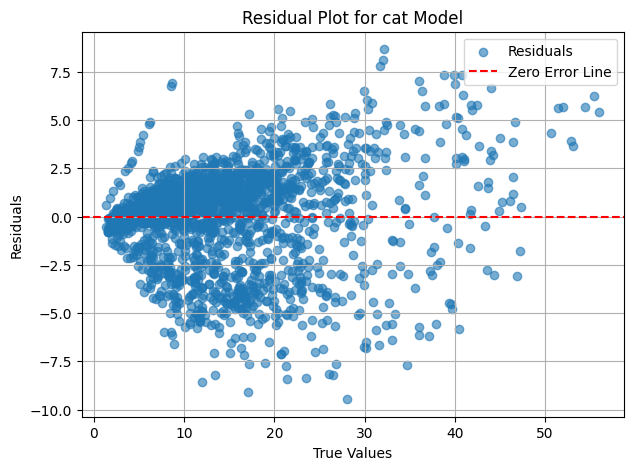

<Figure size 700x500 with 0 Axes>

Text(0.5, 0, 'True Values')

Text(0, 0.5, 'Residuals')

Text(0.5, 1.0, 'Residual Plot for xgb Model')

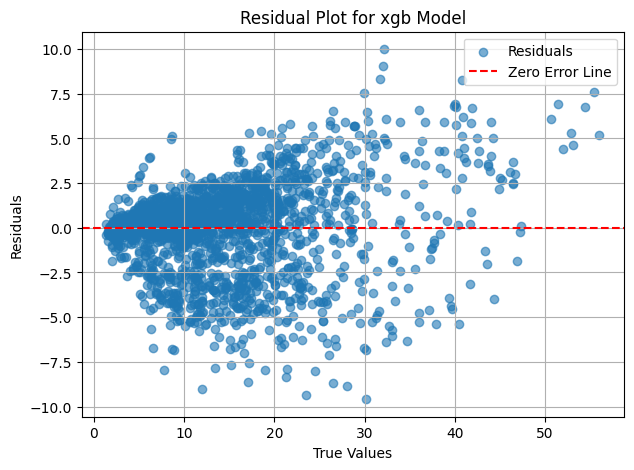

<Figure size 700x500 with 0 Axes>

Text(0.5, 0, 'True Values')

Text(0, 0.5, 'Residuals')

Text(0.5, 1.0, 'Residual Plot for lgb Model')

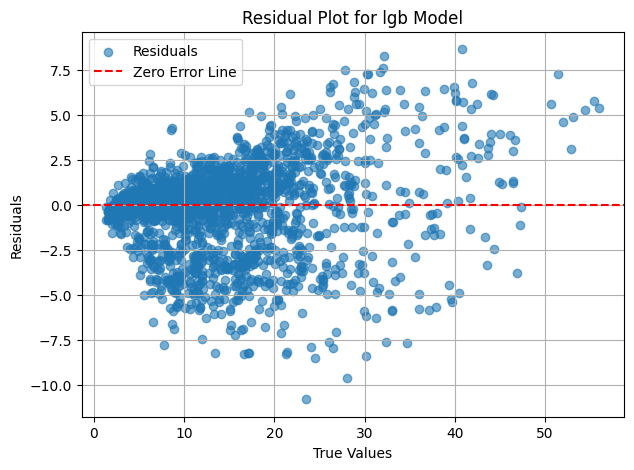

In [ ]:
for model, model_name in zip([cat_handler, xgb_handler, lgb_handler], ["cat", "xgb", "lgb"]):
    df_test = trainer.test_data.copy()

    # Predict on the test set
    predictions = model.model.predict(trainer.X_test)

    # Add predictions and residuals to the test dataframe
    df_test[f"prediction_{model_name}"] = predictions
    df_test[trainer.target] = trainer.y_test.flatten()
    df_test[f"residual_{model_name}"] = df_test[trainer.target] - df_test[f"prediction_{model_name}"]

    # Round numerical values for readability
    df_test[[f"prediction_{model_name}", trainer.target, f"residual_{model_name}"]] = df_test[
        [f"prediction_{model_name}", trainer.target, f"residual_{model_name}"]
    ].round(2)

    # Plot residuals
    plt.figure(figsize=(7, 5))
    plt.scatter(df_test[trainer.target], df_test[f"residual_{model_name}"], alpha=0.6, label="Residuals")
    plt.axhline(0, color='red', linestyle='--', label="Zero Error Line")
    plt.xlabel("True Values")
    plt.ylabel("Residuals")
    plt.title(f"Residual Plot for {model_name} Model")
    plt.legend()
    plt.grid(True)
    plt.show();  # Add semicolon here to suppress the output


## Rest